# Will This Order Arrive Late? · a Purchase-Time Risk Model for Olist

The SQL layer showed that **late orders are 6.8% of deliveries but a third of all 1–2★ reviews**, and the Python deep dive showed that lateness itself costs about 1.9★.
This notebook asks the operational question: **at the moment a customer clicks "buy", can we tell which orders are likely to arrive late?**
If so, those orders can get a longer promise, a faster carrier or a proactive message before the customer is disappointed.

* **Only information known at purchase** is used: where the customer and seller are, the promised delivery date, what is in the basket, and the seller's track record *up to that day*.
* **Tested on the future:** trained on Jan 2017 – Feb 2018, tested on the six months the model never saw (Mar – Aug 2018).
* **Baselines:** the simplest rules (shorter promise, longer distance) and a logistic regression.
* The trained model is exported for the **Streamlit app** (`app` folder), which scores new orders and explains each score.

### Key Findings
* **Lateness can be partly predicted at checkout.** On six months the model never saw, LightGBM reaches **ROC AUC 0.73**, against 0.55–0.59 for single rules (shorter promise, longer distance) and 0.67 for logistic regression.
* **A short daily list catches a lot.** The riskiest 10% of orders hold **28% of all late orders** (20% precision, about 3× the 7% base rate). The riskiest 20% hold 45%.
* **The biggest driver is the promise itself:** orders promised in **10 days or less** carry by far the highest risk. Next come the customer's state (North-East: Alagoas, Paraíba, Maranhão, Sergipe, Bahia), the season, and the **seller's own track record**, with risk rising steeply once a seller's past late rate passes about 5%.
* **What it is worth:** acting on the top 10% over the six test months would have reached about **770 late orders and about 400 low reviews** before they happened.
* The model is exported to the **Streamlit app**, and the saved file scores exactly like the trained model.

In [1]:
# ---- where things live -------------------------------------------------------------------------
import os, sys
from pathlib import Path
os.environ["LOKY_MAX_CPU_COUNT"] = str(max(1, (os.cpu_count() or 2) - 1))   # avoids a harmless joblib warning on Windows

CODE_OVERRIDE = r""   # optional: the folder that contains olistsql.py

def find_module(name):
    if CODE_OVERRIDE:
        hits = sorted(Path(CODE_OVERRIDE).glob(name + "*.py"))
        if hits:
            return hits[0]
    for p in [Path.cwd(), *Path.cwd().parents]:
        hits = sorted(p.glob(name + "*.py"))
        if hits:
            return hits[0]
    home = Path.home()
    for root in [home / "OneDrive" / "Documents", home / "Documents", home / "Downloads", home / "Desktop", home / "OneDrive"]:
        if root.exists():
            try:
                hits = [h for h in root.rglob(name + "*.py") if ".ipynb_checkpoints" not in h.parts]
            except OSError:
                continue
            if hits:
                return sorted(hits, key=lambda f: (len(f.parts), f.name))[0]
    return None

MODULE_FILE = find_module("olistsql")
if MODULE_FILE is None:
    raise FileNotFoundError("olistsql.py not found. Put it in the same folder as this notebook, or paste that folder into CODE_OVERRIDE.")
CODE = MODULE_FILE.parent
os.chdir(CODE)
sys.path.insert(0, str(CODE))
sys.path.insert(0, str(CODE / "app"))
import olistsql as osql
import olistmodel as om
from olisttools import NAVY, BLUE, AMBER, GREEN, RED, PURPLE, CYAN, INK, MUTED, LINE, BLUE_L, RED_L, style_charts

IMAGES = CODE / "images"
IMAGES.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve
style_charts()

# the SQL tables (DuckDB): built once by the SQL notebook, rebuilt here if missing
con = osql.connect("duckdb")
if not osql.table_exists(con, "raw_orders"):
    osql.load_raw(con, CODE / "data")
if not osql.table_exists(con, "fact_orders"):
    osql.run_file(con, "sql/02 clean orders.sql")
print("Code:", CODE.name, "| lightgbm", lgb.__version__, "| shap", shap.__version__)

Code: Olist Deep Dive | lightgbm 4.6.0 | shap 0.49.1


## 1 · Build Purchase-Time Features

The base comes straight from the SQL table `fact_orders`, plus the largest package volume per order from `fact_items`.
The **seller's track record** is computed *as of the day before each purchase* with `merge_asof`: only deliveries already completed count, so no future information leaks in.
Distance is measured between the capitals of the seller's and the customer's states.

In [2]:
o = con.query('''
    SELECT o.order_id, o.purchased_at, o.purchase_date, o.delivered_date, o.customer_state, o.seller_id, o.seller_state,
           o.promised_days, o.items, o.sellers, o.revenue, o.freight, o.weight_g / 1000.0 AS weight_kg,
           v.max_volume_cm3 / 1000.0 AS max_volume_l, o.category, o.is_late, o.days_late, o.review_score
    FROM fact_orders AS o
    LEFT JOIN (SELECT order_id, MAX(product_volume_cm3) AS max_volume_cm3 FROM fact_items GROUP BY order_id) AS v
           ON v.order_id = o.order_id
''')
o["purchased_at"] = pd.to_datetime(o.purchased_at)
o["delivered_date"] = pd.to_datetime(o.delivered_date)
o["is_late"] = o.is_late.astype(bool)
o = o.sort_values("purchased_at").reset_index(drop=True)
o = o.join(om.seller_history(o), on="order_id")

top_categories = o.category.value_counts().index[:30].tolist()
categories = {"customer_state": sorted(o.customer_state.dropna().unique().tolist()),
              "seller_state": sorted(o.seller_state.dropna().unique().tolist()),
              "category": top_categories + ["other"]}
X = om.build_features(o, categories)
y = o.is_late.astype(int)

TRAIN_END = pd.Timestamp("2018-03-01")
train, test = (o.purchased_at < TRAIN_END).values, (o.purchased_at >= TRAIN_END).values
print(f"{len(o):,} delivered orders · {len(om.FEATURES)} features")
print(f"train Jan 2017 – Feb 2018: {train.sum():,} orders ({y[train].mean():.1%} late) · "
      f"test Mar – Aug 2018: {test.sum():,} orders ({y[test].mean():.1%} late)")
X.head(3).T.rename(index=om.LABELS)

96,203 delivered orders · 17 features
train Jan 2017 – Feb 2018: 57,050 orders (6.6% late) · test Mar – Aug 2018: 39,153 orders (7.0% late)


,0,1,2
customer state,PR,PR,PR
seller state,PR,PR,PR
same state,1.0,1.0,1.0
distance (km),0.0,0.0,0.0
promised delivery days,27.0,39.0,39.0
purchase month,1.0,1.0,1.0
purchase weekday,3.0,3.0,3.0
items in order,1.0,1.0,1.0
sellers in order,1.0,1.0,1.0
order value (R$),10.9,10.9,2.9


## 2 · Train and Compare

* **Rule baselines:** "the shorter the promise, the riskier" and "the further away, the riskier".
* **Logistic regression** on the customer state and the numeric features.
* **LightGBM**. Settings were chosen on a validation window inside the training period (Dec 2017 – Feb 2018), before looking at the test months: shallow trees and strong regularisation, because lateness is noisy.

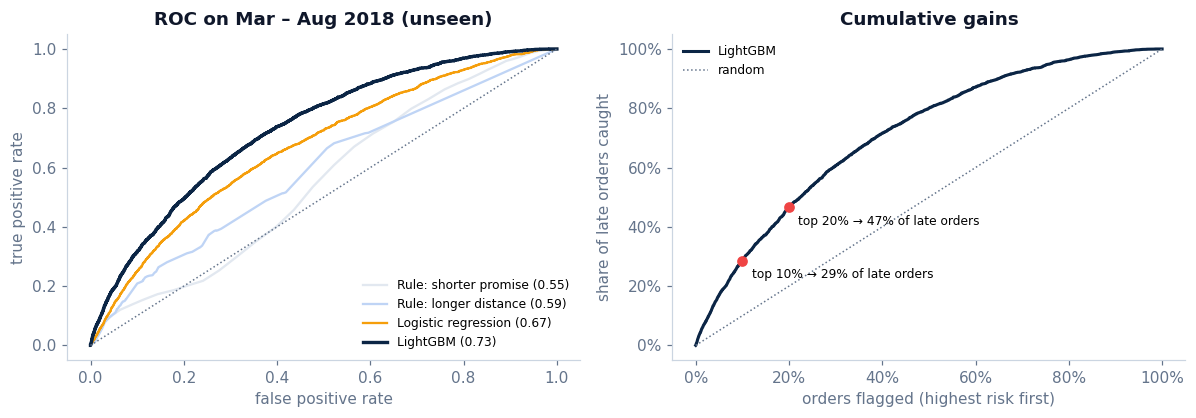

,ROC AUC,PR AUC,late caught in top 10%,precision in top 10%,late caught in top 20%,precision in top 20%
Rule: shorter promise,0.550,0.089,15%,9%,20%,7%
Rule: longer distance,0.589,0.098,21%,14%,31%,10%
Logistic regression,0.670,0.127,23%,16%,40%,14%
LightGBM,0.731,0.170,29%,20%,47%,16%


In [3]:
params = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=200, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=5, n_jobs=1, verbose=-1, random_state=7)
model = lgb.LGBMClassifier(**params).fit(X[train], y[train])
p = model.predict_proba(X[test])[:, 1]

def logit_design(X):
    Z = pd.get_dummies(X[["customer_state"]].astype(str)).astype(float)
    n = X[["distance_km", "promised_days", "items", "revenue", "freight_ratio", "weight_kg", "seller_prior_orders"]].fillna(0).copy()
    for c in ["revenue", "weight_kg", "seller_prior_orders"]:
        n[c] = np.log1p(n[c].clip(lower=0))
    n["seller_late"] = X.seller_prior_late_rate.fillna(y[train].mean())
    n["seller_unknown"] = X.seller_prior_late_rate.isna().astype(float)
    return Z.join(n)
Z = logit_design(X)
scaler = StandardScaler().fit(Z[train])
logit = LogisticRegression(max_iter=3000, C=0.5).fit(scaler.transform(Z[train]), y[train])
p_lr = logit.predict_proba(scaler.transform(Z[test]))[:, 1]

yt = y[test].values
scores = {"Rule: shorter promise": -X.promised_days[test].values, "Rule: longer distance": X.distance_km[test].fillna(0).values,
          "Logistic regression": p_lr, "LightGBM": p}
perf = pd.DataFrame({k: {"ROC AUC": roc_auc_score(yt, v), "PR AUC": average_precision_score(yt, v)} for k, v in scores.items()}).T

def capture(score, share):
    top = score >= np.quantile(score, 1 - share)
    return yt[top].sum() / yt.sum(), yt[top].mean()
for share in (0.1, 0.2):
    perf[f"late caught in top {share:.0%}"] = [capture(v, share)[0] for v in scores.values()]
    perf[f"precision in top {share:.0%}"] = [capture(v, share)[1] for v in scores.values()]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
ax = axes[0]
for (k, v), c in zip(scores.items(), [LINE, BLUE_L, AMBER, NAVY]):
    fpr, tpr, _ = roc_curve(yt, v)
    ax.plot(fpr, tpr, color=c, lw=2.2 if k == "LightGBM" else 1.5, label=f"{k} ({roc_auc_score(yt, v):.2f})")
ax.plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1)
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("ROC on Mar – Aug 2018 (unseen)")
ax = axes[1]
order = np.argsort(-p)
gains = np.cumsum(yt[order]) / yt.sum()
share = np.arange(1, len(p) + 1) / len(p)
ax.plot(share, gains, color=NAVY, lw=2, label="LightGBM")
ax.plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1, label="random")
for s in (0.1, 0.2):
    g = gains[int(s * len(p)) - 1]
    ax.scatter([s], [g], color=RED, zorder=3); ax.text(s + 0.02, g - 0.06, f"top {s:.0%} → {g:.0%} of late orders", fontsize=8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("orders flagged (highest risk first)"); ax.set_ylabel("share of late orders caught"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Cumulative gains")
plt.tight_layout(); save(fig, "model performance"); plt.show()
perf.style.format("{:.3f}", subset=["ROC AUC", "PR AUC"]).format("{:.0%}", subset=[c for c in perf.columns if "top" in c])

**Reading the Comparison**
* **Single rules barely beat chance** (AUC 0.55–0.59). Lateness does not come from one factor.
* **Logistic regression (0.67) helps; LightGBM (0.73) helps more.** The gain comes from thresholds and interactions a linear model cannot draw, such as the jump in risk for promises of 10 days or less, or a short promise to a far-away state.
* **For operations, the gains curve matters most:** flagging 10% of orders catches 28% of late ones, and flagging 20% catches 45%. That is a practical worklist, not a perfect predictor. An AUC of 0.73 is honest for an outcome that also depends on carriers, weather and strikes that are not in the data.

### 2.1 Are the Probabilities Honest?

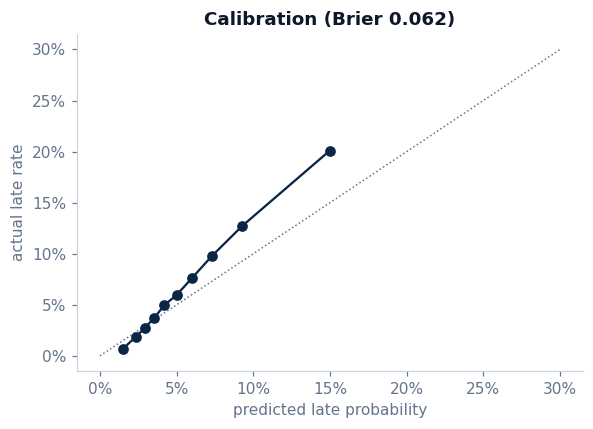

Mean predicted 5.7% vs actual 7.0% in the test months


In [4]:
frac_pos, mean_pred = calibration_curve(yt, p, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot([0, 0.3], [0, 0.3], color=MUTED, ls=":", lw=1)
ax.plot(mean_pred, frac_pos, color=NAVY, marker="o")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("predicted late probability"); ax.set_ylabel("actual late rate")
ax.set_title(f"Calibration (Brier {brier_score_loss(yt, p):.3f})")
plt.tight_layout(); save(fig, "model calibration"); plt.show()
print(f"Mean predicted {p.mean():.1%} vs actual {yt.mean():.1%} in the test months")

**Reading the Calibration:** the curve sits slightly above the diagonal. The model ranks orders well, but **under-estimates** the late rate in the test months (5.8% predicted vs 7.0% actual, and about 20% actual in the riskiest group against 15% predicted). The test period was simply worse than the training period. For ranking a worklist this does not matter. For quoting absolute probabilities, the model would be recalibrated on the latest months.

## 3 · What Drives the Risk? (SHAP)

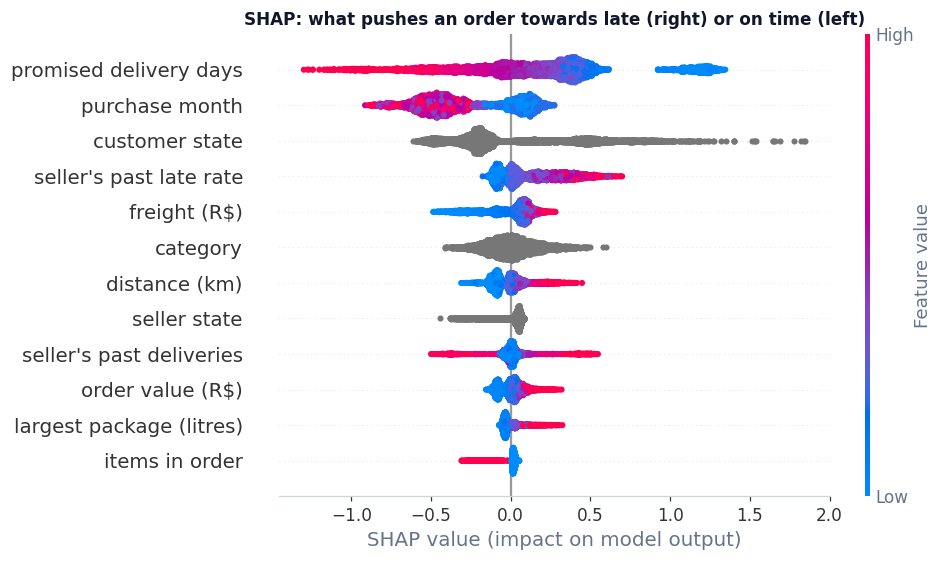

Mean |SHAP| (log-odds):
promised delivery days      0.388
purchase month              0.340
customer state              0.333
seller's past late rate     0.167
freight (R$)                0.114
category                    0.113
distance (km)               0.082
seller state                0.066
seller's past deliveries    0.058
order value (R$)            0.055


In [5]:
explainer = shap.TreeExplainer(model)
sample = X[test].sample(5000, random_state=7)
sv = explainer.shap_values(sample)
sv = sv[1] if isinstance(sv, list) else sv
shown = sample.rename(columns=om.LABELS)
plt.figure()
shap.summary_plot(sv, shown, max_display=12, show=False, plot_size=(9, 5.2))
plt.title("SHAP: what pushes an order towards late (right) or on time (left)", fontsize=11, fontweight="bold")
plt.tight_layout(); save(plt.gcf(), "model shap"); plt.show()

imp = pd.Series(np.abs(sv).mean(axis=0), index=[om.LABELS[c] for c in sample.columns]).sort_values(ascending=False)
print("Mean |SHAP| (log-odds):")
print(imp.round(3).head(10).to_string())

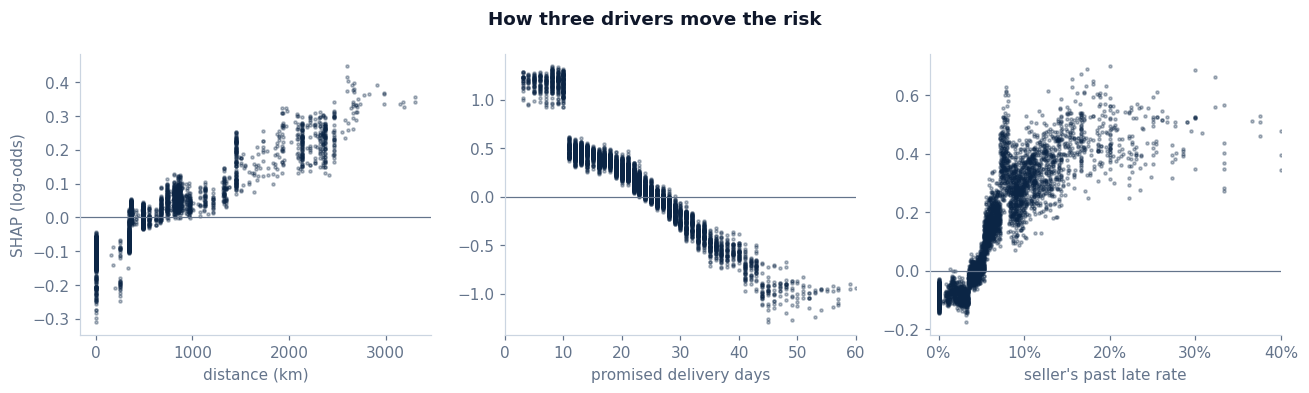

Customer states that add the most risk (mean SHAP): AL +1.58, PB +1.13, MA +1.03, SE +1.00, PE +0.79, BA +0.78


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, f in zip(axes, ["distance_km", "promised_days", "seller_prior_late_rate"]):
    j = list(sample.columns).index(f)
    ax.scatter(sample[f], sv[:, j], s=4, alpha=0.3, color=NAVY)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xlabel(om.LABELS[f]); ax.set_ylabel("SHAP (log-odds)" if f == "distance_km" else "")
    if f == "seller_prior_late_rate":
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_xlim(-0.01, 0.4)
    if f == "promised_days":
        ax.set_xlim(0, 60)
fig.suptitle("How three drivers move the risk", fontweight="bold", color=INK)
plt.tight_layout(); save(fig, "model dependence"); plt.show()

state = (pd.DataFrame({"state": sample.customer_state.astype(str), "shap": sv[:, list(sample.columns).index("customer_state")]})
           .groupby("state").shap.mean().sort_values(ascending=False))
print("Customer states that add the most risk (mean SHAP):", ", ".join(f"{s} {v:+.2f}" for s, v in state.head(6).items()))

**Reading the SHAP Charts**
* **Promised delivery days** is the strongest driver, and it is a sharp threshold: promises of **10 days or less** add about +1.2 to the log-odds, and the risk keeps falling as the promise gets longer. Olist pads most promises (74% of orders arrive 8+ days early), but where it does not, it often misses.
* **Customer state** comes second. The North-East states (Alagoas +1.6, Paraíba, Maranhão, Sergipe, Bahia, Pernambuco) add the most risk, which matches the SQL region analysis.
* **Purchase month** captures peak seasons (Black Friday, Feb–Mar 2018). It is useful but fragile: next year's peaks may fall elsewhere.
* **Seller track record:** risk is flat while a seller's past late rate stays under about 4%, then climbs steeply. This is the same signal as the SQL watch list, now available *before* an order ships.
* Distance, freight and package size add smaller, sensible effects: further, heavier and more expensive to ship means riskier.

## 4 · What Would the Business Do With Tt?

A simple policy: **every day, flag the riskiest 10% of new orders** and act before the customer notices: extend the promise, upgrade the carrier, or send a proactive delay message.
Using the SQL funnel (61% of late orders get a 1–2★ review, against 9% of on-time ones), we can estimate how many low reviews are at stake.

In [7]:
LOW_IF_LATE, LOW_IF_ON_TIME = 0.610, 0.092     # from sql/06 late delivery impact.sql
rows = []
for share in (0.05, 0.10, 0.20):
    top = p >= np.quantile(p, 1 - share)
    late_caught = yt[top].sum()
    rows.append((f"top {share:.0%}", int(top.sum()), int(late_caught), late_caught / yt.sum(), yt[top].mean(),
                 late_caught * (LOW_IF_LATE - LOW_IF_ON_TIME)))
policy = pd.DataFrame(rows, columns=["flag", "orders flagged", "late orders among them", "share of all late", "precision",
                                     "low reviews at stake (if fixed)"])
months = (o.purchased_at[test].max() - o.purchased_at[test].min()).days / 30.44
print(f"Test period: {months:.1f} months, {yt.sum():,} late orders, {test.sum():,} orders")
policy.style.hide(axis="index").format({"orders flagged": "{:,}", "late orders among them": "{:,}", "share of all late": "{:.0%}",
                                        "precision": "{:.0%}", "low reviews at stake (if fixed)": "{:,.0f}"})

Test period: 5.9 months, 2,749 late orders, 39,153 orders


flag,orders flagged,late orders among them,share of all late,precision,low reviews at stake (if fixed)
top 5%,"1,958",467,17%,24%,242
top 10%,"3,916",787,29%,20%,408
top 20%,"7,831","1,285",47%,16%,666


**Reading the Policy Table**
* Flagging the **top 10%** of orders (about 650 a month) reaches **770 late orders** in the test period. If those deliveries were fixed, or the customer warned in time, about **400 low reviews** were at stake.
* Flagging the **top 20%** reaches 45% of late orders, at lower precision (16%). The right cut-off depends on what an action costs: a proactive message is cheap, so a wide list works; a carrier upgrade is expensive, so the top 5% (23% precision) is enough.

## 5 · Export For the App

The final model is retrained on **all** orders (Jan 2017 – Aug 2018) with the same settings, and saved with everything the app needs:
the model file, the category levels, the platform statistics, and each seller's latest track record.

In [8]:
final = lgb.LGBMClassifier(**params).fit(X, y)
om.MODEL_DIR.mkdir(exist_ok=True)
final.booster_.save_model(str(om.MODEL_FILE))

# each seller's track record at the end of the data (what the app uses for a known seller)
hist = (o.dropna(subset=["seller_id"]).groupby(["seller_id", "seller_state"])
          .agg(deliveries=("is_late", "size"), late_rate=("is_late", "mean")).reset_index())
meta = {"features": om.FEATURES, "categories": categories,
        "test_metrics": {"roc_auc": float(roc_auc_score(yt, p)), "pr_auc": float(average_precision_score(yt, p)),
                         "late_caught_top10": float(capture(p, 0.1)[0]), "test_late_rate": float(yt.mean())},
        "platform_late_rate": float(y.mean()), "low_review_if_late": LOW_IF_LATE, "low_review_if_on_time": LOW_IF_ON_TIME,
        "risk_bands": {"low": float(np.quantile(p, 0.5)), "high": float(np.quantile(p, 0.9))},
        "defaults": {"promised_days": float(o.promised_days.median()), "revenue": float(o.revenue.median()),
                     "freight": float(o.freight.median()), "weight_kg": float(o.weight_kg.median()),
                     "max_volume_l": float(o.max_volume_l.median())},
        "trained_on": f"{o.purchased_at.min():%b %Y} – {o.purchased_at.max():%b %Y}", "rows": int(len(o))}
om.META_FILE.write_text(json.dumps(meta, indent=1), encoding="utf-8")

# compact data for the app (no personal data in Olist; customer ids are not exported)
appdata = CODE / "app" / "appdata"
appdata.mkdir(exist_ok=True)
o[["purchase_date", "customer_state", "seller_id", "seller_state", "category", "revenue", "freight", "promised_days",
   "days_late", "is_late", "review_score"]].assign(purchase_date=lambda d: pd.to_datetime(d.purchase_date)).to_parquet(appdata / "orders.parquet", index=False)
hist.to_parquet(appdata / "sellers.parquet", index=False)
print("Saved:", om.MODEL_FILE.name, "·", om.META_FILE.name, "· orders.parquet", f"({(appdata / 'orders.parquet').stat().st_size / 1e6:.1f} MB)",
      "· sellers.parquet", f"({len(hist):,} sellers)")

# check: the exported booster scores like the trained model
chk, _, _ = om.score(lgb.Booster(model_file=str(om.MODEL_FILE)), meta, o.head(200))
print("Max difference vs in-memory model:", float(np.abs(chk - final.predict_proba(X.head(200))[:, 1]).max()))
con.close()

Saved: late model.txt · model meta.json · orders.parquet (1.1 MB) · sellers.parquet (2,936 sellers)
Max difference vs in-memory model: 0.0


## 6 · Summary

| Question | Answer |
|---|---|
| Can lateness be predicted at purchase? | Partly: AUC 0.73 on unseen months; top 10% of orders hold 28% of late ones. |
| What drives it? | Short promises (≤ 10 days), North-East destinations, peak season, sellers with a poor track record. |
| Is it worth it? | About 400 low reviews over six months were reachable with a top-10% worklist. |
| How is it used? | Exported to the Streamlit app, which scores a new order and explains the score. |

**Recommendations**
1. **Never promise 10 days or less** to North-East states, or to sellers with a late rate above 5%.
2. **Run a daily top-10% worklist** of risky orders for proactive messages or carrier upgrades.
3. **Feed the seller track record into seller onboarding and ranking**, together with the SQL watch list.

### Limitations
* **Only delivered orders** are in the data with a known outcome. Cancelled or lost orders, often the worst experiences, are not modelled.
* **Operational shocks are not in the features.** The Feb–Mar 2018 spike and the May 2018 truckers' strike in Brazil came from outside the order data. Adding carrier, warehouse and weather data would raise the ceiling.
* Distance is between **state capitals**, not actual addresses. Zip-code geolocation would sharpen it.